In [1]:
from urllib.request import urlretrieve

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
urlretrieve(url, "course_lead_scoring_2026.csv")

('course_lead_scoring_2026.csv', <http.client.HTTPMessage at 0x259152b8a50>)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [4]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [6]:
df.shape

(5000, 9)

In [7]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [8]:
categorical_columns = ["lead_source", "industry", "employment_status", "location"] 
Numerical_columns = ["annual_income", "number_of_courses_viewed",
                  "interaction_count", "lead_score"]

In [9]:
for c in categorical_columns:
    df[c] = df[c].fillna("NA")
for c in Numerical_columns:
    df[c] = df[c].fillna(0.0)


In [11]:
y = df["converted"]
X = df.drop(columns=["converted"])

In [13]:
from sklearn.model_selection import train_test_split

In [14]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [ ]:
df_full_train.head()




,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
913,social_media,technology,student,south_america,0.0,1,1,0.26,0
1288,paid_ads,education,employed,north_america,63357.0,4,7,0.73,1
3551,social_media,healthcare,employed,north_america,72351.0,2,3,0.33,1
2532,organic_search,technology,student,south_america,41501.0,2,2,0.41,1
2678,organic_search,education,employed,NA,44817.0,3,7,0.73,0


In [20]:
df_test.shape

(1000, 9)

In [19]:
df_train.shape

(3000, 9)

In [18]:
df_val.head()
df_val.shape

(1000, 9)

In [21]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [22]:
y_train = df_train["converted"].values
y_val = df_val["converted"].values
y_test = df_test["converted"].values

In [24]:
del df_train["converted"]
del df_val["converted"]
del df_test["converted"]

In [25]:
df_val.shape

(1000, 8)

Question 1, AUC as feature importance.

In [26]:
from sklearn.metrics import roc_auc_score

In [27]:
roc_auc_score(y_train, df_train['lead_score'])

0.7882254810906102

In [28]:
roc_auc_score(y_train, df_train['number_of_courses_viewed'])

0.7229894623989618

In [29]:
roc_auc_score(y_train, df_train['interaction_count'])

0.7649203047563227

In [30]:
roc_auc_score(y_train, df_train['annual_income'])

0.6081977776250831

Question 2: train the model and get the validation AUC.

In [32]:
train_dicts = df_train[categorical_columns + Numerical_columns].to_dict(orient='records')
val_dicts = df_val[categorical_columns + Numerical_columns].to_dict(orient='records')

In [33]:
train_dicts[0]

{'lead_source': 'paid_ads',
 'industry': 'technology',
 'employment_status': 'employed',
 'location': 'asia',
 'annual_income': 80198.0,
 'number_of_courses_viewed': 5,
 'interaction_count': 9,
 'lead_score': 0.91}

In [34]:
len(train_dicts)

3000

In [35]:
len(val_dicts)

1000

In [36]:
from sklearn.feature_extraction import DictVectorizer

In [37]:
dv = DictVectorizer(sparse=False)
x_train = dv.fit_transform(train_dicts)
x_val = dv.transform(val_dicts)

In [38]:
x_train.shape

(3000, 28)

In [39]:
x_val.shape

(1000, 28)

now training the model and getting the AUC

In [43]:
from sklearn.linear_model import LogisticRegression

In [44]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(x_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [47]:
y_pred = model.predict_proba(x_val)[:, 1]
y_pred

array([0.54472295, 0.79005195, 0.50977888, 0.52913938, 0.82072019,
       0.54245978, 0.50178713, 0.54698387, 0.82553293, 0.40583733,
       0.91301563, 0.33581814, 0.30789865, 0.42704779, 0.62192278,
       0.53665458, 0.41931919, 0.8408734 , 0.79969125, 0.61790114,
       0.61625178, 0.68059917, 0.85605897, 0.80784866, 0.62046001,
       0.45970706, 0.54556701, 0.41221376, 0.72714009, 0.46812074,
       0.77222177, 0.79043875, 0.61433884, 0.78549747, 0.49753408,
       0.66077272, 0.69804752, 0.76896541, 0.65657489, 0.64127891,
       0.665091  , 0.57942805, 0.67830933, 0.61186093, 0.86890227,
       0.41469666, 0.84130124, 0.74229353, 0.68028534, 0.71891427,
       0.86417925, 0.64043353, 0.54246981, 0.70225149, 0.27894887,
       0.70826476, 0.62310694, 0.47781746, 0.37914009, 0.69936028,
       0.52032854, 0.69977689, 0.75148934, 0.58087484, 0.47001787,
       0.56863469, 0.91297179, 0.79972019, 0.82206539, 0.36140186,
       0.66132383, 0.52330043, 0.79295458, 0.72068066, 0.71234

In [48]:
y_val

array([0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0,
       0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1,
       0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0,
       0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0,
       1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0,
       1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1,

In [46]:
auc = roc_auc_score(y_val, y_pred)
print('val AUC = %.3f' % auc)

val AUC = 0.732


Question 3, precision and recall at many thresholds.

In [49]:
scores = []
thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))

In [50]:
len(scores)

101

In [53]:
df_pr = pd.DataFrame(scores, columns=['threshold', 'tp', 'fp', 'fn', 'tn'])

In [52]:
scores[0]

(np.float64(0.0), np.int64(586), np.int64(414), np.int64(0), np.int64(0))

In [54]:
df_pr['precision'] = df_pr.tp / (df_pr.tp + df_pr.fp)
df_pr['recall'] = df_pr.tp / (df_pr.tp + df_pr.fn)

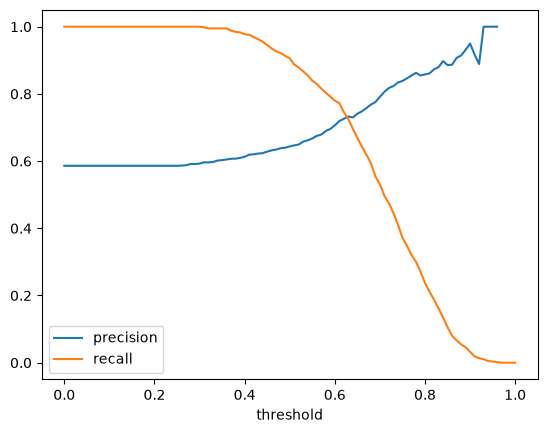

In [55]:
plt.plot(df_pr.threshold, df_pr.precision, label='precision')
plt.plot(df_pr.threshold, df_pr.recall, label = 'recall')
plt.xlabel('threshold')
plt.legend()

In [56]:
valid = df_pr.dropna(subset=['precision'])

In [61]:
valid = valid[(valid.precision > 0) | (valid.recall > 0)]
diff = (valid.precision - valid.recall).abs()
row = valid.loc[diff.idxmin(), ['threshold', 'precision', 'recall']]
row.round(2)
#print('val AUC = %.3f' % auc)

threshold    0.63
precision    0.73
recall       0.73
Name: 63, dtype: float64

Question 4: F1 score. It combines precision and recall into one number, and you find the threshold where that number is highest.

In [62]:
df_pr['f1'] = 2 * df_pr.precision * df_pr.recall /(df_pr.precision + df_pr.recall)

In [64]:
df_pr.head()


,threshold,tp,fp,fn,tn,precision,recall,f1
0,0.00,586,414,0,0,0.586,1.0,0.738966
1,0.01,586,414,0,0,0.586,1.0,0.738966
2,0.02,586,414,0,0,0.586,1.0,0.738966
3,0.03,586,414,0,0,0.586,1.0,0.738966
4,0.04,586,414,0,0,0.586,1.0,0.738966


In [65]:
df_pr.tail()

,threshold,tp,fp,fn,tn,precision,recall,f1
96,0.96,1,0,585,414,1.0,0.001706,0.003407
97,0.97,0,0,586,414,NaN,0.000000,NaN
98,0.98,0,0,586,414,NaN,0.000000,NaN
99,0.99,0,0,586,414,NaN,0.000000,NaN
100,1.00,0,0,586,414,NaN,0.000000,NaN


In [66]:
round(df_pr.loc[df_pr.f1.idxmax()], 2)

threshold      0.41
tp           572.00
fp           352.00
fn            14.00
tn            62.00
precision      0.62
recall         0.98
f1             0.76
Name: 41, dtype: float64

Question 5, 5-fold cross-validation

In [67]:
from sklearn.model_selection import KFold

In [68]:
from sklearn.model_selection import KFold

def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical_columns + Numerical_columns].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model


def predict(df, dv, model):
    dicts = df[categorical_columns + Numerical_columns].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [69]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    y_tr = df_tr.converted.values
    y_va = df_va.converted.values

    dv, model = train(df_tr, y_tr)
    y_pred = predict(df_va, dv, model)

    auc = roc_auc_score(y_va, y_pred)
    scores.append(auc)

print(scores)
print(round(np.std(scores), 3))

[0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
0.007


In [70]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        y_tr = df_tr.converted.values
        y_va = df_va.converted.values

        dv, model = train(df_tr, y_tr, C=C)
        y_pred = predict(df_va, dv, model)

        auc = roc_auc_score(y_va, y_pred)
        scores.append(auc)

    print('C=%s  mean=%.3f  std=%.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06  mean=0.617  std=0.019
C=0.001  mean=0.749  std=0.010
C=1  mean=0.732  std=0.007
